# 00 · Research setup and data audit

**Advanced movement representation learning — chapter 0.** Status: `AUTHORED — AWAITING USER EXECUTION` (2026-10-11). Nothing in this notebook has been run by its author; every table and figure below appears only when you execute the cells.

## Research objective
Establish, before any model exists, exactly which athletes, attempts and NFL outcomes are available, what the machine can run, and how athletes are split — so that no later result can depend on a choice made after seeing it.

## Hypothesis
None is tested here. This chapter fixes facts and rules. The programme's hypotheses (H1–H5: a sequence encoder learns repeatable movement information that the stopwatch does not hold and that transfers to NFL movement) are all open.

## Input datasets and grain
| Dataset | Grain | Used for |
|---|---|---|
| `gold/phase_03/combine_frame_kinematics` | Combine frame (event_id, nfl_id, attempt, ts), 10 Hz | sequences |
| `gold/phase_03/combine_trajectory_quality` | Combine attempt | quality tier |
| `gold/sprint_rescue/attempt_censoring_diagnostics` | forty attempt | usable tier, recording-window flags |
| `gold/mart_athlete_research_base` | athlete | position, cohort, official Combine results |
| `gold/fact_nfl_play_participation` + `silver/games` | tracked player-play | NFL exposure per athlete (aggregated in DuckDB) |
| `gold/combine_nfl_dl/athlete_targets` | athlete × window | availability of the executed DL get-off target |

No NFL tracking frame is loaded in this notebook.

## What this notebook saves
`schema_inventory`, `sequence_manifest`, `athlete_registry`, `dataset_audit`, `missingness_matrix`, `split_registry`, `leakage_audit`, `research_metadata.json` and seven figures (`AM00_*`). Locations are printed by the setup cell.

## How to run
Run the cells top to bottom. Start with `RUN_MODE = 'smoke'` (about 60 athletes, outputs under `…/advanced_movement/_sample`), read the outputs, then set `RUN_MODE = 'full'`, restart the kernel and run again. No terminal is needed.

## Configuration
The only cell you edit. Smoke mode never writes into the full-run folders, and a full run never reads smoke artifacts.

In [1]:
RUN_MODE = 'full'        # 'smoke' = small athlete subset, outputs under */_sample · 'full' = every athlete
FORCE_REBUILD = False     # True = ignore compatible cached artifacts and recompute
SAVE_FIGURES = True       # PNG 300 DPI + SVG (+ PDF for the main figures) with plot data and metadata
SAVE_TABLES = True        # CSV tables and Parquet datasets with schema sidecars
SAVE_MODELS = True        # no model in this notebook; kept so every notebook exposes the same controls
DEVICE = 'auto'           # 'auto' | 'cpu' | 'cuda'
SEED = 20261011
NUM_WORKERS = 0
BATCH_SIZE = 32
MAX_EPOCHS = 3

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime, duckdb_connect

cfg = Phase01Config.load()
configure_runtime(cfg)    # thread and memory limits; call before the first polars import of the kernel

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.frames import query_df
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import validation
from nflbdb.research.advanced_movement import visualizations as viz
from nflbdb.research.advanced_movement.artifacts import AdvStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES,
                                save_tables=SAVE_TABLES, save_models=SAVE_MODELS, device=DEVICE, seed=SEED,
                                num_workers=NUM_WORKERS, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
store = AdvStore(cfg, controls)

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(110)
display(Markdown(f'**Run mode: `{controls.run_mode}`** — outputs go to:'))
display(store.describe())

**Run mode: `full`** — outputs go to:

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_movement"""
"""datasets (Parquet + schema sidecar)""","""warehouse/gold/advanced_movement"""
"""figures (PNG 300 DPI, SVG, PDF)""","""reports/figures/advanced_movement"""
"""models and fitted preprocessing""","""artifacts/models/advanced_movement"""


## A · Environment

The notebooks never install anything. A missing required package stops the cell with the action to take. PyTorch is only needed from notebook 03; if it is absent it is reported here and nothing below fails.

**Scale to keep in mind.** The sprint reliability rescue (executed) counted 793 forty-yard-dash attempts of 418 athletes, 375 of them with a repeat, 47–58 frames per attempt. As a padded float32 array with 11 channels that is roughly 793 × 60 × 11 × 4 bytes ≈ 2 MB. Memory is not the constraint of this programme; the number of independent athletes is.

In [3]:
display(pl.DataFrame(amc.check_dependencies()))
display(pl.DataFrame(amc.environment_report()))

device = amc.resolve_device(controls.device)
nondeterminism = amc.seed_everything(controls.seed)
display(Markdown(f'Resolved device: `{device}` · seed: `{controls.seed}`'))
display(Markdown('**Known sources of nondeterminism**\n\n' + '\n'.join(f'- {n}' for n in nondeterminism)))

package,version,status,needed_for
str,str,str,str
"""numpy""","""2.2.6""","""ok""","""all notebooks"""
"""polars""","""2.0.0""","""ok""","""all notebooks"""
"""duckdb""","""1.5.6""","""ok""","""all notebooks"""
"""pyarrow""","""25.0.1""","""ok""","""all notebooks"""
"""matplotlib""","""3.10.7""","""ok""","""all notebooks"""
"""psutil""","""7.1.0""","""ok""","""all notebooks"""
"""torch""","""""","""MISSING""","""notebook 03 onwards (TCN, GRU, LSTM)"""


item,value
str,str
"""python""","""3.10.18"""
"""executable""","""c:\Users\myben\.conda\envs\nfl\python.exe"""
"""platform""","""Windows-10-10.0.26300-SP0"""
"""cpu_count""","""16"""
"""ram_total_gb""","""15.4"""
"""ram_available_gb""","""0.6"""
"""torch""","""NOT INSTALLED — required from notebook 03"""


Resolved device: `cpu` · seed: `20261011`

**Known sources of nondeterminism**

- Polars group_by output order is not guaranteed: every builder sorts explicitly
- NumPy generators are created per task from the seed (no reliance on the global state)
- PyTorch not installed: nothing to seed there

### Synthetic validation of the code used below

These checks run in this process on small synthetic sprint curves with a known answer (split integrity, padding and masks, fold-safe normalisation, the four alignments, the artifact store). They touch no project data and write only inside a temporary folder that they delete. The cell stops if any check fails. A tiny test figure is displayed by the last check.

13:39:39 | WARNING | nflbdb.research.advanced_movement.data | [advanced_movement] sprint-rescue attempt table missing: usable tier taken from quality_tier, recording-window flags are null
13:39:39 | WARNING | nflbdb.research.advanced_movement.data | [advanced_movement] sprint-rescue attempt table missing: usable tier taken from quality_tier, recording-window flags are null
13:39:39 | WARNING | nflbdb.research.advanced_movement.data | [advanced_movement] sprint-rescue attempt table missing: usable tier taken from quality_tier, recording-window flags are null
13:39:39 | WARNING | nflbdb.research.advanced_movement.data | [advanced_movement] sprint-rescue attempt table missing: usable tier taken from quality_tier, recording-window flags are null
13:39:39 | WARNING | nflbdb.research.advanced_movement.data | [advanced_movement] sprint-rescue attempt table missing: usable tier taken from quality_tier, recording-window flags are null
13:39:39 | WARNING | nflbdb.research.advanced_movement.data 

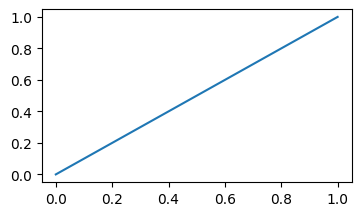

check,status,detail
str,str,str
"""controls_and_device""","""PASS""","""run mode and device are validated; smoke keeps every scientific parameter"""
"""manifest_and_registry_contracts""","""PASS""","""51 sequences, 24 athletes; contracts hold and the flow is nested"""
"""split_integrity""","""PASS""","""24 athletes; outer and inner folds are disjoint, attempts never straddle a fold"""
"""leakage_is_detected""","""PASS""","""an athlete on both sides, a duplicated key and an unassigned sequence are all reported"""
"""smoke_subset_is_grouped""","""PASS""","""the smoke subset is a deterministic set of ATHLETES; all attempts of a chosen athlete follow him"""
"""sequence_channels_and_invariance""","""PASS""","""channels are unchanged by rotating and translating the field; frame 0 anchors time and distance"""
"""padding_and_masks""","""PASS""","""43 sequences of 45–55 frames; padding is zero, masked and refused when violated"""
"""scaler_uses_training_athletes_only""","""PASS""","""statistics ignore held-out athletes, padding and undefined values; the scaler knows whom it has seen"""
"""time_alignments""","""PASS""","""elapsed time reproduces the frames and stops at the last one; normalised time spans first to last frame"""


In [4]:
validation_report = validation.run_all()
display(validation_report)
validation.assert_all_passed(validation_report)

## B · Existing warehouse

Presence, size and columns of every persisted dataset the programme reads. A dataset listed as `MISSING` is documented, never guessed or rebuilt here. Row counts come from Parquet metadata, so the 22-million-row NFL tracking table is counted without being scanned.

In [5]:
inventory = amd.schema_inventory(cfg)     # never cached: it is a snapshot of what is on disk right now
if controls.save_tables:
    inventory = store.write(inventory, amd.SCHEMAS, 'SCHEMAS', {'run_mode': controls.run_mode})
display(inventory.select('dataset', 'layer', 'status', 'n_files', 'rows', 'n_columns'))

missing_datasets = inventory.filter(pl.col('status') == 'MISSING')['dataset'].to_list()
display(Markdown('**Missing datasets:** ' + (', '.join(f'`{d}`' for d in missing_datasets) if missing_datasets else 'none')))

13:39:48 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:SCHEMAS] schema_inventory: 23 rows → warehouse/gold/advanced_movement/schema_inventory.parquet


dataset,layer,status,n_files,rows,n_columns
str,str,str,i64,i64,i64
"""silver.combine_tracking""","""silver""","""present""",3,463189,17
"""silver.combine_results""","""silver""","""present""",1,510,20
"""silver.game_tracking""","""silver""","""present""",3,22654290,22
"""silver.player_play""","""silver""","""present""",1,314197,39
"""silver.plays""","""silver""","""present""",1,114954,34
"""silver.games""","""silver""","""present""",1,1002,10
"""gold.dim_athlete""","""gold""","""present""",1,510,21
"""gold.fact_combine_attempt""","""gold""","""present""",1,6310,17
"""gold.fact_nfl_play_participation""","""gold""","""present""",3,314944,16


**Missing datasets:** none

In [6]:
# Columns of the frame-level source of every sequence (the dataset the encoders will read).
frame_row = inventory.filter(pl.col('dataset') == 'phase_03.combine_frame_kinematics')
if frame_row.height and frame_row['status'][0] == 'present':
    display(Markdown('**`combine_frame_kinematics` columns:** ' + frame_row['columns'][0]))
display(pl.DataFrame([{'channel': c.name, 'unit': c.unit, 'kind': c.kind, 'proposed_input': c.default, 'meaning': c.meaning}
                      for c in amc.CHANNELS]))

**`combine_frame_kinematics` columns:** event_id, nfl_id, attempt, drill_type, drill_name, drill, seg_idx, pos, seg_len, frame_id, ts, t_s, dt_ms, break_reason, x, y, s, a, dir, step_yds, x_s, y_s, vx, vy, speed, ax, ay, accel_mag, a_tan, a_lat, yaw_rate, curvature, heading, step_smooth, pos_resid, valid_kin, heading_valid

channel,unit,kind,proposed_input,meaning
str,str,str,bool,str
"""t_rel""","""s""","""clock""",false,"""seconds since the first valid frame of the recording"""
"""dist""","""yd""","""geometry""",false,"""smoothed path length since the first valid frame"""
"""along""","""yd""","""geometry""",false,"""progress along the straight line from first to last frame"""
"""speed""","""yd/s""","""kinematic""",true,"""magnitude of the smoothed velocity"""
"""a_tan""","""yd/s²""","""kinematic""",true,"""rate of change of speed (signed)"""
"""a_lat""","""yd/s²""","""kinematic""",true,"""lateral acceleration (signed; mirror-dependent)"""
"""yaw_rate""","""deg/s""","""kinematic""",false,"""rate of change of the direction of motion"""
"""lat_dev""","""yd""","""geometry""",true,"""sideways deviation from the first-to-last line"""
"""head_sin""","""–""","""geometry""",false,"""sine of the direction of motion relative to the run line"""


In [7]:
# DuckDB census of the Combine frames by drill (all athletes, independent of RUN_MODE).
inputs_all = amd.AdvInputs(cfg, acfg)
con = duckdb_connect(cfg)
try:
    drill_census = query_df(con, f'''
        SELECT drill,
               count(*) AS n_frames,
               count(DISTINCT (event_id, nfl_id, attempt)) AS n_attempts,
               count(DISTINCT nfl_id) AS n_athletes,
               round(avg(CASE WHEN valid_kin THEN 1.0 ELSE 0.0 END), 4) AS share_valid_frames
        FROM {inputs_all.frames_sql()}
        GROUP BY drill ORDER BY n_attempts DESC''')
finally:
    con.close()
display(drill_census)

drill,n_frames,n_attempts,n_athletes,share_valid_frames
str,i64,i64,i64,f64
"""FORTY_YARD_DASH""",41500,793,418,1.0
"""GAUNTLET_DRILL""",38228,404,267,1.0
"""BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION""",21569,241,122,1.0
"""PASS_RUSH_DROP""",10752,239,120,1.0
"""PASS_RUSH_DRILL""",10285,225,118,1.0
"""SHORT_SHUTTLE""",11690,223,170,1.0
"""LINE_DRILL""",15447,217,118,1.0
"""THREE_CONE_DRILL""",15951,203,160,1.0
"""OVER_SHOULDER_ADJUST""",9559,147,142,1.0


## C · Data census

**Units.** The *athlete* is the independent unit. A *sequence* is one Combine attempt; an athlete has one to a few, and they are not independent. A *frame* is a 100 ms sample and is never a sample size.

**Eligibility of a sequence** (fixed here, before any model): the drill is the forty-yard dash; the attempt is in the usable quality tier of the executed sprint rescue; the longest segment with defined derivatives has at least `min_frames` frames. Excluded sequences keep a row with the reason.

In smoke mode a seeded subset of athletes is used; all attempts of a chosen athlete stay together.

In [8]:
athlete_subset = (amd.smoke_subset(inputs_all.primary_athletes(), acfg.smoke_athletes, controls.seed)
                  if controls.smoke else None)
inputs = amd.AdvInputs(cfg, acfg, athlete_subset)
CENSUS = [amd.MANIFEST, amd.ATHLETES, amd.AUDIT, amd.MISSING]


def build_census():
    mart = inputs.mart()
    manifest = amd.sequence_manifest(inputs.frames(), inputs.trajectory_quality(), inputs.rescue_attempts(), mart, acfg)
    athletes = amd.athlete_registry(mart, manifest, inputs.nfl_exposure(), inputs.getoff_targets(), acfg)
    return {amd.MANIFEST.name: manifest, amd.ATHLETES.name: athletes,
            amd.AUDIT.name: amd.dataset_audit(athletes, manifest, acfg), amd.MISSING.name: amd.missingness_matrix(athletes)}


census = store.build('CENSUS', CENSUS, build_census, params={'config': acfg.params(), 'athletes': athlete_subset},
                     files=inputs.input_files())
manifest, athletes = census[amd.MANIFEST.name], census[amd.ATHLETES.name]
audit, missing = census[amd.AUDIT.name], census[amd.MISSING.name]
display(Markdown(f'**{athletes.height} athletes · {manifest.height} Combine attempts (all drills) · '
                 f'{manifest.filter(pl.col("eligible_primary")).height} eligible forty sequences**'))

13:39:56 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:CENSUS] computing (never run)
13:39:56 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:CENSUS] sequence_manifest: 6,310 rows → warehouse/gold/advanced_movement/sequence_manifest.parquet
13:39:56 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:CENSUS] athlete_registry: 510 rows → warehouse/gold/advanced_movement/athlete_registry.parquet
13:39:56 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:CENSUS] dataset_audit: 229 rows → warehouse/gold/advanced_movement/dataset_audit.parquet
13:39:56 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:CENSUS] missingness_matrix: 48 rows → warehouse/gold/advanced_movement/missingness_matrix.parquet


**510 athletes · 6310 Combine attempts (all drills) · 793 eligible forty sequences**

### C.1 Dataset flow and intersections
Each stage adds its condition to the previous one. The last stages are the athletes available to a Combine → NFL comparison at each exposure threshold.

item,n_athletes,note
str,i64,str
"""01_combine_athletes""",510,"""athletes with a Combine results row or a tracked sequence"""
"""02_primary_sequence""",418,"""… with ≥ 1 eligible FORTY_YARD_DASH sequence"""
"""03_official_times""",418,"""… AND official forty + 10-yard split"""
"""04_nfl_any""",407,"""… AND ≥ 1 tracked NFL play (any season type)"""
"""05_nfl_reg""",332,"""… AND ≥ 1 tracked regular-season play"""
"""06_nfl_reg_ge_20""",314,"""… AND ≥ 20 regular-season plays"""
"""07_nfl_reg_ge_50""",285,"""… AND ≥ 50 regular-season plays"""
"""08_nfl_reg_ge_100""",253,"""… AND ≥ 100 regular-season plays"""


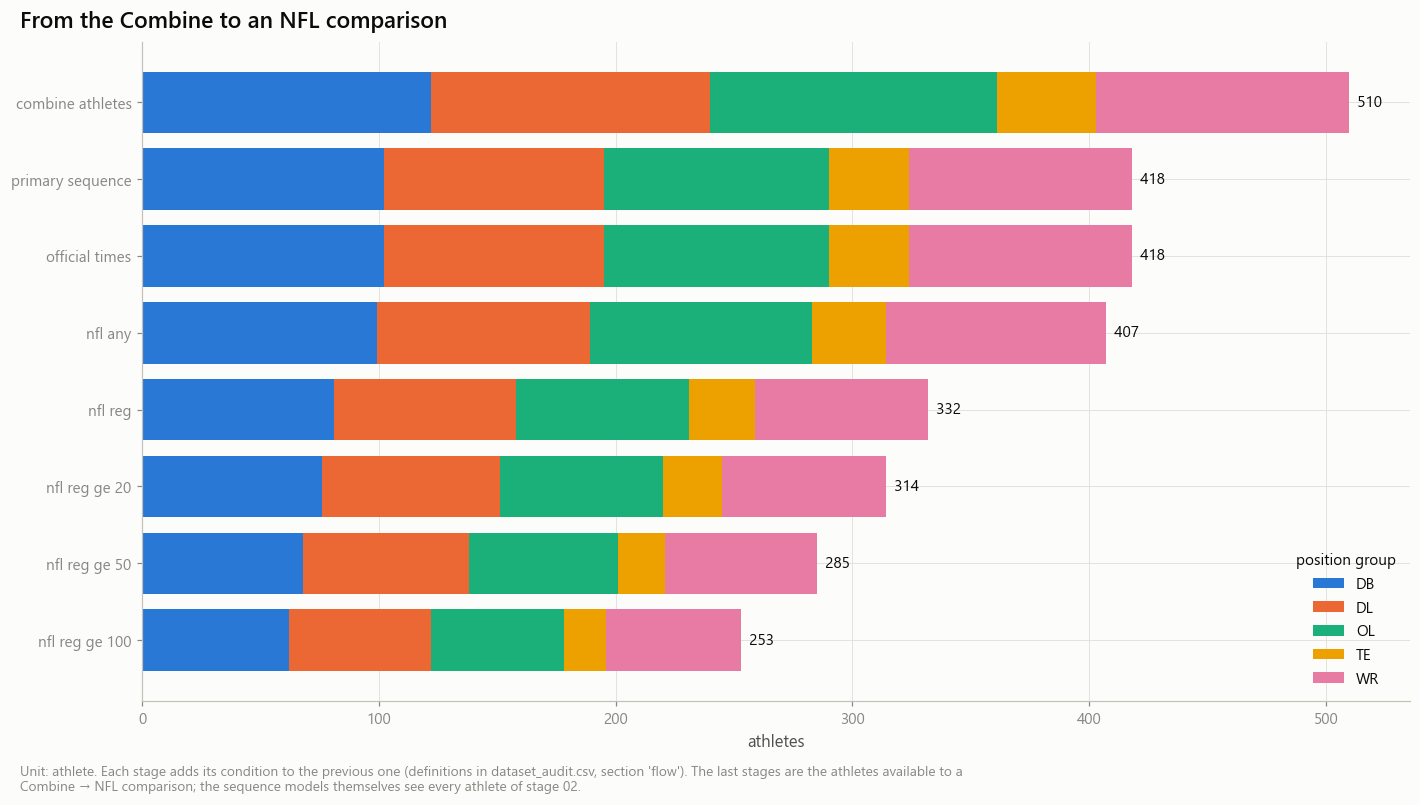

In [9]:
flow = audit.filter(pl.col('section') == 'flow').sort('item').select('item', pl.col('value').cast(pl.Int64).alias('n_athletes'), 'note')
display(flow)
store.show(viz.plot_dataset_flow(audit), 'AM00_01_dataset_flow', {'flow': audit.filter(pl.col('section').str.starts_with('flow'))},
           publication=True, source='dataset_audit', n=f'{athletes.height} athletes')

In [10]:
# Reconciliation with counts measured by earlier executed reports (full mode only: a smoke subset cannot match them).
expected = {'eligible forty sequences': 793, 'athletes with a forty sequence': 418, 'athletes with a repeated forty': 375}
seq_rows = audit.filter((pl.col('section') == 'sequences') & (pl.col('item') == 'primary_eligible'))
measured = {'eligible forty sequences': seq_rows.filter(pl.col('metric') == 'n_sequences')['value'][0],
            'athletes with a forty sequence': seq_rows.filter(pl.col('metric') == 'n_athletes')['value'][0],
            'athletes with a repeated forty': audit.filter(pl.col('section') == 'repeat')['value'][0]}
recon = pl.DataFrame([{'quantity': k, 'sprint_rescue_report': v, 'this_run': int(measured[k]),
                       'matches': (int(measured[k]) == v) if not controls.smoke else None} for k, v in expected.items()])
display(recon)
if controls.smoke:
    display(Markdown('_Smoke mode: the subset is not expected to reproduce the full counts._'))

quantity,sprint_rescue_report,this_run,matches
str,i64,i64,bool
"""eligible forty sequences""",793,793,true
"""athletes with a forty sequence""",418,418,true
"""athletes with a repeated forty""",375,375,true


### C.2 Athletes by position and draft cohort

item,n_athletes,n_with_primary_sequence,n_with_repeat,n_nfl_reg
str,f64,f64,f64,f64
"""DB""",122.0,102.0,93.0,96.0
"""DL""",118.0,93.0,84.0,98.0
"""OL""",121.0,95.0,84.0,91.0
"""TE""",42.0,34.0,32.0,33.0
"""WR""",107.0,94.0,82.0,83.0


item,n_athletes,n_with_primary_sequence,n_with_repeat,n_nfl_reg
str,f64,f64,f64,f64
"""2023""",160.0,138.0,124.0,132.0
"""2024""",177.0,147.0,122.0,144.0
"""2025""",173.0,133.0,129.0,125.0


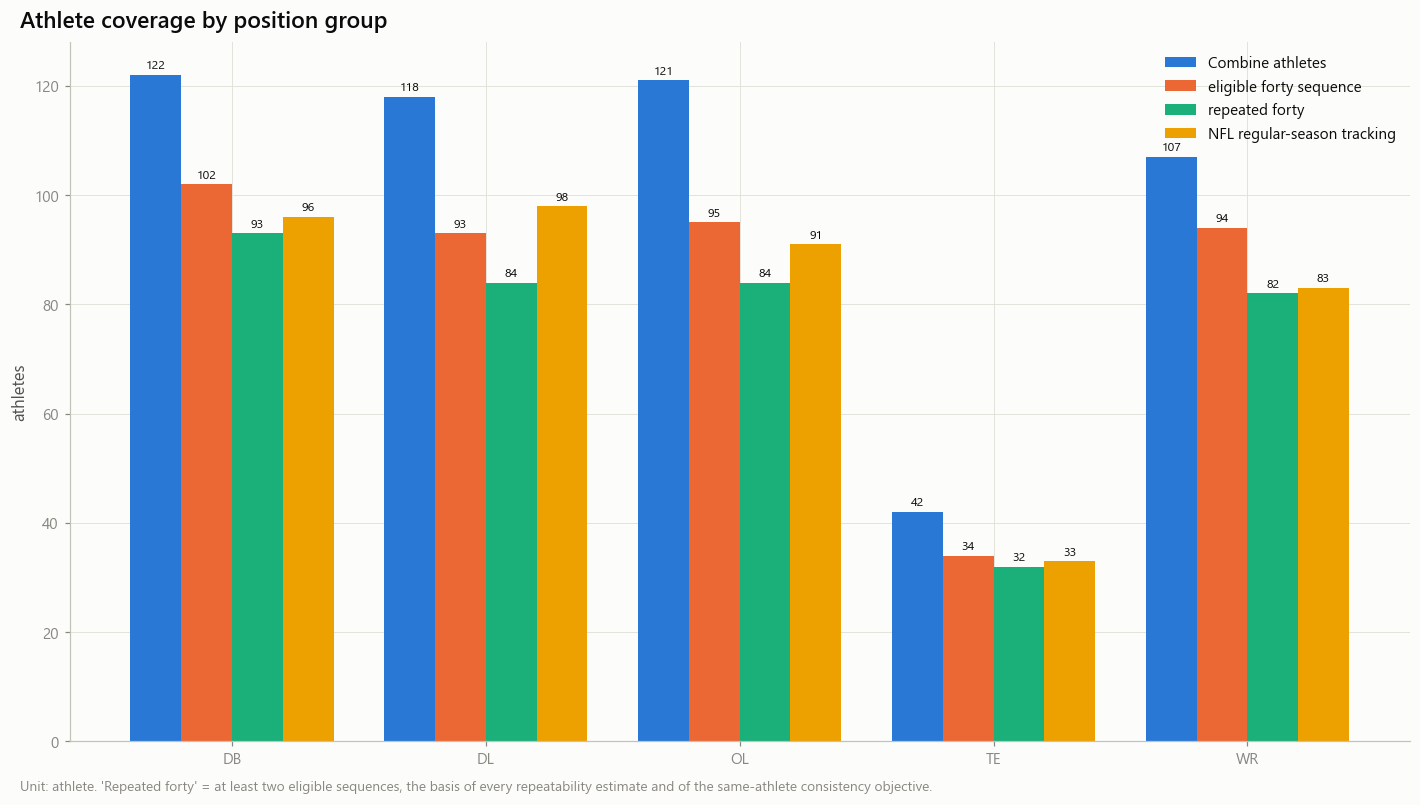

In [11]:
for section in ('athletes_by_position_group', 'athletes_by_draft_year'):
    display(audit.filter(pl.col('section') == section).pivot(on='metric', index='item', values='value').sort('item'))
store.show(viz.plot_coverage_by_position(audit), 'AM00_02_athlete_coverage_by_position',
           {'coverage': audit.filter(pl.col('section') == 'athletes_by_position_group')},
           source='dataset_audit', n=f'{athletes.height} athletes')

### C.3 Attempts per athlete and frames per attempt

item,value,note
str,f64,str
"""1""",43.0,"""eligible primary sequences per athlete"""
"""2""",375.0,"""eligible primary sequences per athlete"""


metric,primary_all,primary_eligible
str,f64,f64
"""n_sequences""",793.0,793.0
"""n_athletes""",418.0,418.0
"""longest_valid_p05""",48.0,48.0
"""longest_valid_p50""",51.0,51.0
"""longest_valid_p95""",59.0,59.0
"""longest_valid_min""",45.0,45.0
"""longest_valid_max""",90.0,90.0
"""duration_s_p05""",4.7,4.7
"""duration_s_p50""",5.0,5.0


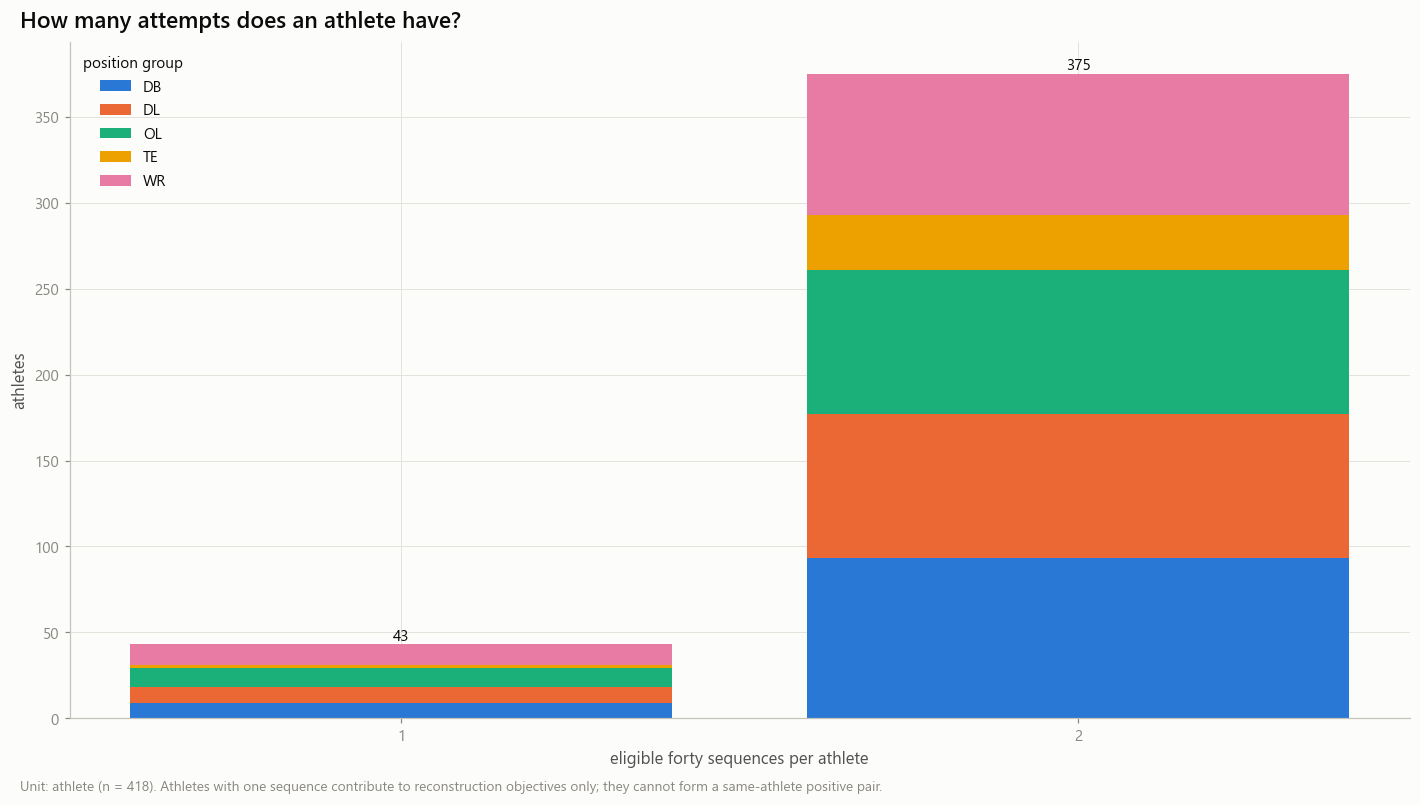

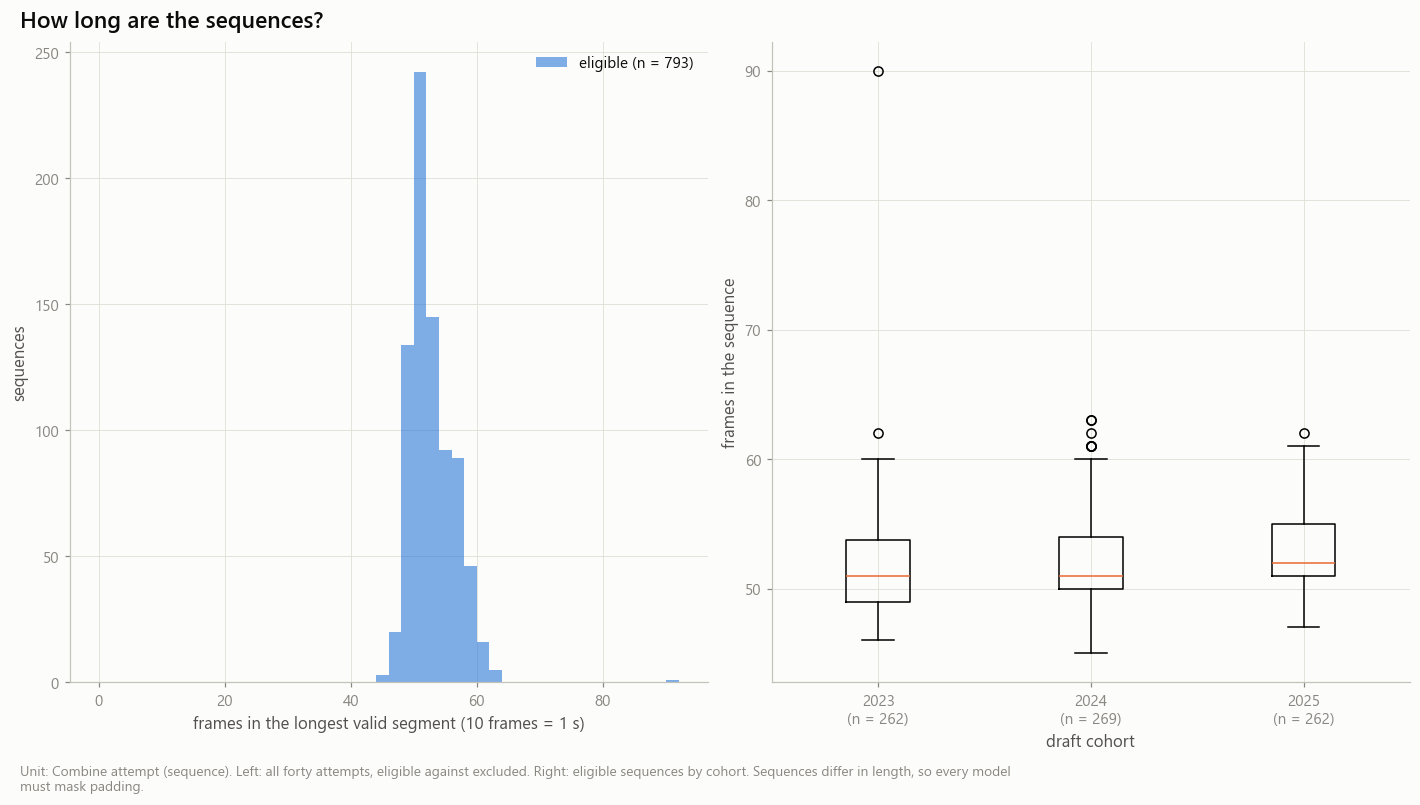

In [12]:
display(audit.filter(pl.col('section') == 'attempts_per_athlete').select('item', 'value', 'note'))
display(audit.filter(pl.col('section') == 'sequences').pivot(on='item', index='metric', values='value'))
store.show(viz.plot_attempt_counts(athletes), 'AM00_03_attempt_count_distribution',
           {'athletes': athletes.select('nfl_id', 'position_group', 'n_primary_eligible')},
           source='athlete_registry', n=f'{athletes.filter(pl.col("n_primary_eligible") >= 1).height} athletes')
store.show(viz.plot_sequence_lengths(manifest, acfg.primary_drill), 'AM00_04_sequence_length_distribution',
           {'sequences': manifest.filter(pl.col('drill') == acfg.primary_drill).select('seq_id', 'draft_year', 'longest_valid', 'eligible_primary')},
           source='sequence_manifest', n=f'{manifest.filter(pl.col("drill") == acfg.primary_drill).height} forty attempts')

### C.4 Drill coverage, quality tiers, exclusions and recording-window flags

In [13]:
display(audit.filter(pl.col('section') == 'drill_coverage').pivot(on='metric', index='item', values='value').sort('n_sequences', descending=True))
display(audit.filter(pl.col('section').is_in(['quality_tier_primary', 'exclusions_primary'])).select('section', 'item', 'value'))
display(audit.filter(pl.col('section') == 'flags_primary_eligible').select('item', 'value', 'note'))

item,n_sequences,n_athletes
str,f64,f64
"""FORTY_YARD_DASH""",793.0,418.0
"""GAUNTLET_DRILL""",404.0,267.0
"""BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION""",241.0,122.0
"""PASS_RUSH_DROP""",239.0,120.0
"""PASS_RUSH_DRILL""",225.0,118.0
"""SHORT_SHUTTLE""",223.0,170.0
"""LINE_DRILL""",217.0,118.0
"""THREE_CONE_DRILL""",203.0,160.0
"""OVER_SHOULDER_ADJUST""",147.0,142.0


section,item,value
str,str,f64
"""quality_tier_primary""","""A""",793.0
"""exclusions_primary""","""eligible""",793.0


item,value,note
str,f64,str
"""onset_censored""",0.58512,"""793 sequences with the flag"""
"""signal_flag""",0.07314,"""793 sequences with the flag"""
"""structural_flag""",0.010088,"""793 sequences with the flag"""
"""boundary_peak""",0.153846,"""793 sequences with the flag"""
"""fit_ok""",0.955864,"""793 sequences with the flag"""
"""S0_all""",1.0,"""793 sequences with the flag"""
"""S1_structural""",0.989912,"""793 sequences with the flag"""
"""S2_signal""",0.925599,"""793 sequences with the flag"""
"""S3_no_boundary""",0.796974,"""793 sequences with the flag"""


### C.5 Cohort exposure and NFL outcome availability

Later cohorts have had fewer seasons, so NFL exposure and draft cohort are confounded. The get-off rows concern defensive linemen only, and the vendor definition of `player_get_off` is still unresolved (`configs/player_get_off_definition.json`): it is counted here as an available number, nothing more.

item,n_athletes,note
str,i64,str
"""reg_plays_ge_20""",314,"""tracked regular-season plays (movement-envelope targets, notebook 07)"""
"""getoff_obs_ge_20""",74,"""valid player_get_off observations (DL only; vendor definition unresolved)"""
"""reg_plays_ge_50""",285,"""tracked regular-season plays (movement-envelope targets, notebook 07)"""
"""getoff_obs_ge_50""",64,"""valid player_get_off observations (DL only; vendor definition unresolved)"""
"""reg_plays_ge_100""",253,"""tracked regular-season plays (movement-envelope targets, notebook 07)"""
"""getoff_obs_ge_100""",53,"""valid player_get_off observations (DL only; vendor definition unresolved)"""


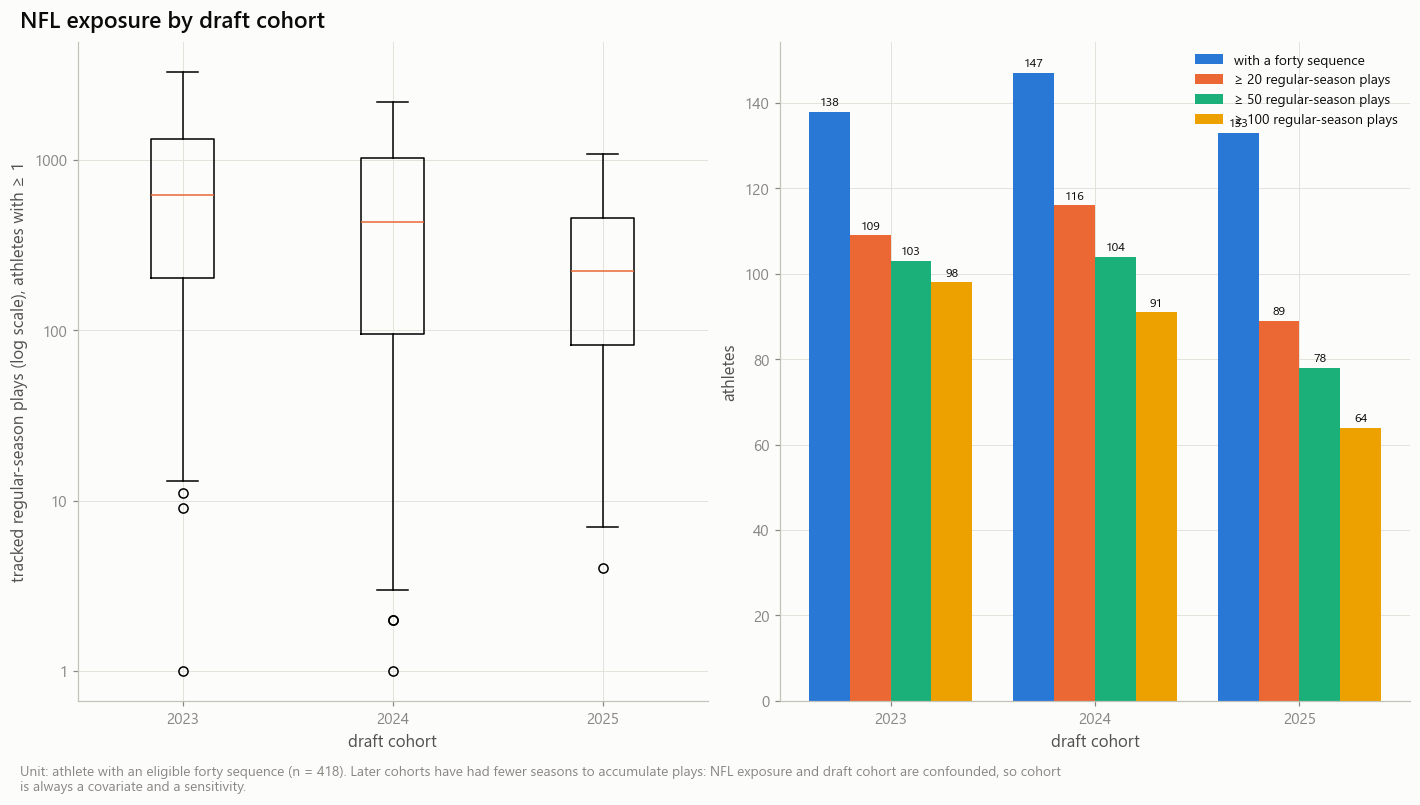

In [14]:
display(audit.filter(pl.col('section') == 'nfl_outcomes').select('item', pl.col('value').cast(pl.Int64).alias('n_athletes'), 'note'))
store.show(viz.plot_cohort_exposure(athletes, acfg.nfl_min_plays_grid), 'AM00_05_cohort_exposure',
           {'athletes': athletes.select('nfl_id', 'draft_year', 'position_group', 'nfl_reg_plays', 'nfl_reg_games', 'n_primary_eligible')},
           source='athlete_registry', n=f'{athletes.height} athletes')

### C.6 Missingness

variable,ALL,DB,DL,OL,TE,WR
str,f64,f64,f64,f64,f64,f64
"""cmb_forty""",0.168627,0.147541,0.20339,0.214876,0.190476,0.093458
"""cmb_ten_yd_split""",0.166667,0.147541,0.20339,0.206612,0.190476,0.093458
"""cmb_combine_weight""",0.0,0.0,0.0,0.0,0.0,0.0
"""cmb_combine_height""",0.0,0.0,0.0,0.0,0.0,0.0
"""primary_sequence""",0.180392,0.163934,0.211864,0.214876,0.190476,0.121495
"""repeat_sequence""",0.264706,0.237705,0.288136,0.305785,0.238095,0.233645
"""nfl_regular_season""",0.213725,0.213115,0.169492,0.247934,0.214286,0.224299
"""getoff_observations""",0.807843,1.0,0.169492,1.0,1.0,1.0


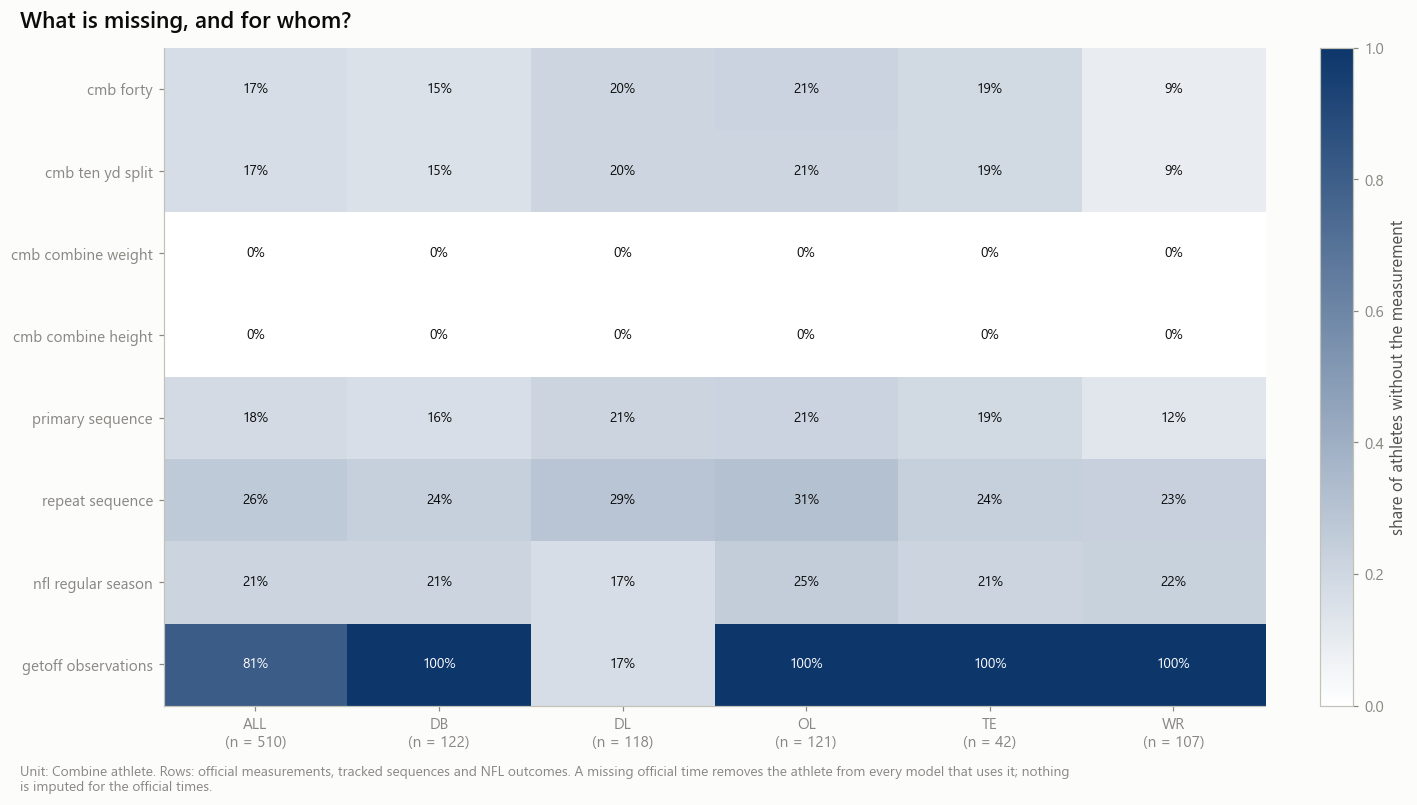

In [15]:
display(missing.pivot(on='group', index='variable', values='share_missing'))
store.show(viz.plot_missingness(missing), 'AM00_06_missingness_heatmap', {'missingness': missing},
           source='missingness_matrix', n=f'{athletes.height} athletes')

## D · Split registry

Created once, persisted, and reused by every later notebook. It uses position group and draft cohort only: no Combine measurement and no NFL value can influence a fold.

| Term | Definition used in this programme |
|---|---|
| **Outer fold** | Repeated K-fold over athletes. The held-out athletes of a fold are the test set of the primary evaluation. |
| **Inner fold** | A second fold label. For outer test fold *k* the development split is taken among athletes with `outer_fold ≠ k`. Architectures, objectives and hyperparameters are selected there. |
| **INDUCTIVE** (primary) | Encoder, normalisation, component selection and prediction head are fitted without ANY data of the held-out athletes — their Combine sequences included. The encoder is refitted inside each outer training fold. |
| **TRANSDUCTIVE** (secondary, always labelled) | The encoder also sees the Combine sequences of the held-out athletes, never their NFL data. Reported separately; never called held-out performance. |
| **Design subset** | A fixed stratified ~30 % of athletes on which preprocessing choices of notebook 01 are quantified; the other athletes show whether the choice holds. With repeated K-fold every athlete is held out once, so a choice made on all athletes is transductive by construction — the design subset keeps that exposure explicit and small. |

$$\text{for every repeat } r:\quad \bigcup_{k} T_{r,k} = A,\qquad T_{r,k} \cap T_{r,k'} = \varnothing \;(k \neq k'),\qquad \text{all sequences of an athlete share his fold.}$$

Rule for later chapters: outer-fold results are looked at once per pre-specified analysis. Anything redesigned after seeing them is labelled exploratory.

13:40:28 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:SPLITS] computing (never run)
13:40:28 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:SPLITS] split_registry: 1,254 rows → warehouse/gold/advanced_movement/split_registry.parquet
13:40:28 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:SPLITS] leakage_audit: 7 rows → warehouse/gold/advanced_movement/leakage_audit.parquet


check,passed,n_violations,detail
str,bool,i64,str
"""one_outer_fold_per_athlete_and_repeat""",true,0,"""the registry key (nfl_id, repeat) is unique"""
"""every_eligible_sequence_has_a_fold""",true,0,"""eligible sequences whose athlete is absent from the registry"""
"""all_attempts_of_an_athlete_share_a_fold""",true,0,"""athlete × repeat combinations whose sequences fall in more than one outer fold"""
"""every_outer_fold_is_populated""",true,0,"""fold sizes 83–84 athletes"""
"""inner_folds_partition_every_outer_training_set""",true,0,"""missing development folds inside outer training sets"""
"""design_role_is_constant_per_athlete""",true,0,"""125 design athletes of 418"""
"""split_uses_position_and_cohort_only""",true,0,"""stratum = position group | draft cohort; no measurement, no NFL value"""


outer_fold,held_out_athletes,of_which_design
i64,u32,u32
0,84,23
1,84,28
2,84,21
3,83,18
4,83,35


Example — repeat 0, outer fold 0: **334 training · 84 held-out** athletes; inside the training set, inner fold 0: **248 fit · 86 development**.

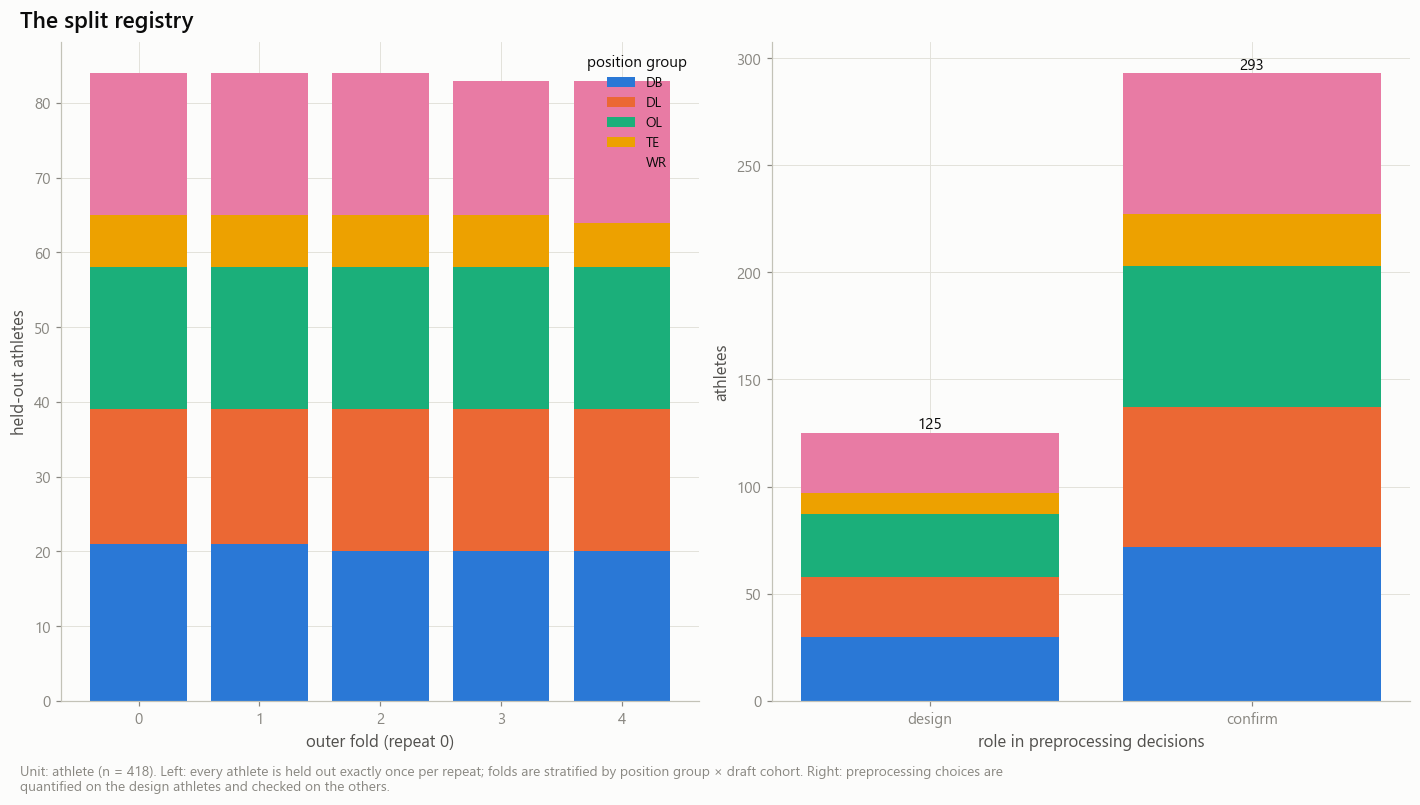

In [16]:
def build_splits():
    splits = amd.build_split_registry(athletes, acfg, controls.seed)
    return {amd.SPLITS.name: splits, amd.LEAKAGE.name: amd.leakage_audit(splits, manifest, acfg)}


split_out = store.build('SPLITS', [amd.SPLITS, amd.LEAKAGE], build_splits,
                        params={'config': acfg.params(), 'seed': controls.seed, 'athletes': athlete_subset},
                        files=[store.parquet(amd.ATHLETES), store.parquet(amd.MANIFEST)])
splits, leakage = split_out[amd.SPLITS.name], split_out[amd.LEAKAGE.name]
display(leakage)
if not leakage['passed'].all():
    raise amd.LeakageError('the split registry failed its audit: ' + ', '.join(leakage.filter(~pl.col('passed'))['check'].to_list()))

display(splits.filter(pl.col('repeat') == 0).group_by('outer_fold').agg(
    pl.len().alias('held_out_athletes'), (pl.col('design_role') == 'design').sum().alias('of_which_design')).sort('outer_fold'))
train_ids, test_ids = amd.fold_athletes(splits, repeat=0, outer_fold=0)
fit_ids, dev_ids = amd.inner_athletes(splits, repeat=0, outer_fold=0, inner_fold=0)
display(Markdown(f'Example — repeat 0, outer fold 0: **{len(train_ids)} training · {len(test_ids)} held-out** athletes; '
                 f'inside the training set, inner fold 0: **{len(fit_ids)} fit · {len(dev_ids)} development**.'))
store.show(viz.plot_split_balance(splits, athletes), 'AM00_07_split_registry',
           {'splits': splits.filter(pl.col('repeat') == 0)}, source='split_registry',
           n=f'{splits["nfl_id"].n_unique()} athletes')

## Reusable metadata
One small JSON file that later notebooks read to confirm they continue the same run (mode, seed, configuration, counts).

In [17]:
metadata = {'notebook': '00_research_setup_and_data_audit', 'seed': controls.seed, 'config': acfg.params(), 'device': device,
            'n_athletes': athletes.height, 'n_athletes_with_sequence': splits['nfl_id'].n_unique(),
            'n_eligible_sequences': manifest.filter(pl.col('eligible_primary')).height,
            'missing_datasets': missing_datasets, 'validation_checks_passed': validation_report.height,
            'getoff_definition_status': 'unresolved — see configs/player_get_off_definition.json'}
if controls.save_tables:
    display(Markdown(f'Saved `{cfg.paths.rel(store.write_json("research_metadata", metadata))}`'))

outputs = [amd.SCHEMAS, amd.MANIFEST, amd.ATHLETES, amd.AUDIT, amd.MISSING, amd.SPLITS, amd.LEAKAGE]
display(pl.DataFrame([{'output': c.name, 'kind': c.kind, 'grain': c.area, 'key': ', '.join(c.key),
                       'saved': store.exists(c), 'path': cfg.paths.rel(store.parquet(c))} for c in outputs]))

Saved `warehouse/gold/advanced_movement/research_metadata.json`

output,kind,grain,key,saved,path
str,str,str,str,bool,str
"""schema_inventory""","""table""","""dataset""","""dataset""",true,"""warehouse/gold/advanced_movement/schema_inventory.parquet"""
"""sequence_manifest""","""dataset""","""Combine attempt (event_id, nfl_id, attempt)""","""seq_id""",true,"""warehouse/gold/advanced_movement/sequence_manifest.parquet"""
"""athlete_registry""","""dataset""","""athlete""","""nfl_id""",true,"""warehouse/gold/advanced_movement/athlete_registry.parquet"""
"""dataset_audit""","""table""","""section × item × metric""","""section, item, metric""",true,"""warehouse/gold/advanced_movement/dataset_audit.parquet"""
"""missingness_matrix""","""table""","""variable × position group""","""variable, group""",true,"""warehouse/gold/advanced_movement/missingness_matrix.parquet"""
"""split_registry""","""dataset""","""athlete × split repeat""","""nfl_id, repeat""",true,"""warehouse/gold/advanced_movement/split_registry.parquet"""
"""leakage_audit""","""table""","""check""","""check""",true,"""warehouse/gold/advanced_movement/leakage_audit.parquet"""


## Interpretation
_To be written after execution. Placeholders — do not fill from expectation._

- **Coverage:** _how many athletes carry a sequence, a repeat, an NFL outcome at each threshold; which position groups are thin._
- **Reconciliation:** _do the counts match the sprint rescue report (full mode)? If not, why._
- **Exposure:** _how strongly NFL exposure depends on draft cohort._
- **Missingness:** _which measurements limit the modelling population._

## Limitations
- The census counts availability. It says nothing about the validity of any NFL endpoint; the vendor definition of `player_get_off` is unresolved.
- Athletes reach NFL exposure thresholds only if they were drafted, kept and played. That selection is not corrected anywhere in this programme.
- The usable quality tier and the recording-window flags come from the executed sprint rescue; if that table is absent the cell above says so and falls back to the Phase 03 tier.
- The design subset limits, but does not remove, the exposure of preprocessing choices to athletes that are later held out.

## Decision for the next notebook
_After reading the executed outputs:_ confirm that the leakage audit passed, that the eligible-sequence counts are as expected, and that the split sizes are acceptable. Then open `01_sequence_eda_and_alignment.ipynb` with the **same `RUN_MODE`**.